# Лабораторная работа №6. Лемматизация и векторизация текстов

**Цель работы:** освоить методы предобработки текстовых данных (очистка, лемматизация, стемминг) и базовые методы векторизации (мешок слов, N-граммы, TF-IDF), применить их для разведочного анализа текстового корпуса из 25 отзывов о фильмах.


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import pymorphy3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv('data/reviews.csv')
print('Размер датасета:', df.shape)
print('Пустых значений в text:', df['text'].isna().sum())
df.head()

Размер датасета: (25, 3)
Пустых значений в text: 0


,id,text,rating
0,1,Отличный фильм! Сюжет захватывает с первых мин...,9
1,2,"Скучно и затянуто, еле досмотрел до конца. Бол...",2
2,3,Превосходная игра актёров! Особенно главный ге...,10
3,4,"УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил ...",1
4,5,Замечательная режиссура и красивые пейзажи. См...,8


In [2]:
def clean_text(text):
    text = text.lower()                                # нижний регистр
    text = re.sub(r'https?://\S+|www\.\S+', '', text)  # ссылки
    text = re.sub(r'<[^>]+>', '', text)                # HTML-теги
    text = re.sub(r'#\S+', '', text)                  # хэштеги
    text = re.sub(r'\d+', '', text)                   # цифры
    text = re.sub(r'[^а-яё\s]', '', text)             # только русские буквы и пробелы
    text = re.sub(r'\s+', ' ', text).strip()          # схлопывание повторных пробелов
    return text

df['text_clean'] = df['text'].apply(clean_text)
print(df[['text', 'text_clean']].head(3).to_string())

                                                                                   text                                                                         text_clean
0            Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.            отличный фильм сюжет захватывает с первых минут актёры играют прекрасно
1  Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.  скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра
2  Превосходная игра актёров! Особенно главный герой — просто находка для этого фильма.   превосходная игра актёров особенно главный герой просто находка для этого фильма


### Примеры до / после

In [3]:
for i in [4, 9, 22]:
    print(f'--- id {df.loc[i, "id"]} ---')
    print('ДО   :', df.loc[i, 'text'])
    print('ПОСЛЕ:', df.loc[i, 'text_clean'])
    print()

--- id 5 ---
ДО   : Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!
ПОСЛЕ: замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул

--- id 10 ---
ДО   : Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.
ПОСЛЕ: слабый фильм сюжет предсказуем с первых минут очень жаль потраченного времени

--- id 23 ---
ДО   : Смотрел трейлер на https://example.com/trailer2 — и разочаровался. Всё интересное было в трейлере.
ПОСЛЕ: смотрел трейлер на и разочаровался всё интересное было в трейлере



### Лемматизация ч/з pymorphy3

In [4]:
morph = pymorphy3.MorphAnalyzer()

def lemmatize(text):
    return ' '.join(morph.parse(w)[0].normal_form for w in text.split())

df['text_prepared'] = df['text_clean'].apply(lemmatize)

### Примеры до / после

In [5]:
for i in [0, 1, 2, 6, 8]:
    print(f'--- id {df.loc[i, "id"]} ---')
    print('ДО   :', df.loc[i, 'text_clean'])
    print('ПОСЛЕ:', df.loc[i, 'text_prepared'])
    print()

--- id 1 ---
ДО   : отличный фильм сюжет захватывает с первых минут актёры играют прекрасно
ПОСЛЕ: отличный фильм сюжет захватывать с первый минута актёр играть прекрасно

--- id 2 ---
ДО   : скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра
ПОСЛЕ: скучно и затянутый еле досмотреть до конец большой не быть смотреть такой режиссёр

--- id 3 ---
ДО   : превосходная игра актёров особенно главный герой просто находка для этого фильма
ПОСЛЕ: превосходный игра актёр особенно главный герой просто находка для это фильм

--- id 7 ---
ДО   : один из лучших фильмов года обязательно смотрите попадание в настроение
ПОСЛЕ: один из хороший фильм год обязательно смотреть попадание в настроение

--- id 9 ---
ДО   : великолепно пересматривал три раза и каждый раз нахожу чтото новое
ПОСЛЕ: великолепно пересматривать три раз и каждый раз находить чтоть новый



### Размер словаря до и после обработки

In [6]:
raw_vocab = set(' '.join(df['text_clean']).split())
prep_vocab = set(' '.join(df['text_prepared']).split())
print('Уникальных слов до лемматизации:', len(raw_vocab))
print('Уникальных слов после лемматизации:', len(prep_vocab))
print('Сокращение словаря: {:.1f}%'.format((1 - len(prep_vocab) / len(raw_vocab)) * 100))

Уникальных слов до лемматизации: 186
Уникальных слов после лемматизации: 162
Сокращение словаря: 12.9%


### Выводы по заданию 1

Очистка убрала ссылки, HTML-теги, хэштеги, цифры и пунктуацию, оставив только русские буквы. Лемматизация приводит словоформы к начальной форме (словарная форма): `захватывает -> захватывать`, `актёры -> актёр`, `минут -> минута`.

Я выбрал лемматизацию вместо стемминга, потому что она даёт грамматически корректные (словарные) формы слов — это удобнее для чтения и интерпретации ключевых слов и частот. Стемминг лишь «обрезает» окончания и может давать несуществующие формы (например, `фильм` и `фильме` сведутся к одному корню, но и смыслово разные слова с общим корнем тоже могут слиться). Для небольшого корпуса отзывов лемматизация через `pymorphy3` работает быстро и качественно.

Словарь сократился со 186 до 162 уникальных слов (на 12.9%), поскольку разные словоформы одного слова свелись к одной лемме.



---

## Задание 2. Мешок слов и N-граммы

In [7]:
cv1 = CountVectorizer()
X1 = cv1.fit_transform(df['text_prepared'])
print('2.1 CountVectorizer():', X1.shape)

cv2 = CountVectorizer(ngram_range=(1, 2))
X2 = cv2.fit_transform(df['text_prepared'])
print('2.2 CountVectorizer(ngram_range=(1,2)):', X2.shape)

cv3 = CountVectorizer(min_df=2, max_df=0.9)
X3 = cv3.fit_transform(df['text_prepared'])
print('2.3a CountVectorizer(min_df=2, max_df=0.9):', X3.shape)

cv4 = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X4 = cv4.fit_transform(df['text_prepared'])
print('2.3b CountVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9):', X4.shape)

2.1 CountVectorizer(): (25, 157)
2.2 CountVectorizer(ngram_range=(1,2)): (25, 370)
2.3a CountVectorizer(min_df=2, max_df=0.9): (25, 42)
2.3b CountVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9): (25, 46)


In [8]:
pd.DataFrame({
    'Вариант': ['CountVectorizer()',
                'CountVectorizer(ngram_range=(1,2))',
                'CountVectorizer(min_df=2, max_df=0.9)',
                'CountVectorizer(ngram_range=(1,2), min_df=2, max_df=0.9)'],
    'Размерность': [str(X1.shape), str(X2.shape), str(X3.shape), str(X4.shape)],
    'Число признаков': [X1.shape[1], X2.shape[1], X3.shape[1], X4.shape[1]],
    'Число документов': [X1.shape[0]] * 4
})

,Вариант,Размерность,Число признаков,Число документов
0,CountVectorizer(),"(25, 157)",157,25
1,"CountVectorizer(ngram_range=(1,2))","(25, 370)",370,25
2,"CountVectorizer(min_df=2, max_df=0.9)","(25, 42)",42,25
3,"CountVectorizer(ngram_range=(1,2), min_df=2, m...","(25, 46)",46,25


### Выводы по заданию 2

- `CountVectorizer()` строит матрицу 25 * 157 - это мешок слов: каждая колонка - отдельное слово, каждая ячейка - число вхождений слова в документ.
- Добавление биграмм увеличило словарь до 25 * 370: признаками стали и одиночные слова, и соседние пары слов, например `еле досмотреть` и `играть прекрасно`. Словарь вырос в 2.4 раза, потому что каждая соседняя пара слов стала отдельным признаком.
- Фильтры `min_df=2` (слово должно встретиться минимум в 2 документах) и `max_df=0.9` (слово должно встречаться не более чем в 90% документов) резко сжали словарь, до 42 признаков для униграмм и 46 для униграмм+биграмм. Из словаря исчезли редкие слова (встретившиеся лишь один раз) и очень частые служебные слова, которые встречаются почти во всех документах и не несут различительной силы.



---

## Задание 3. TF-IDF

In [9]:
# В задании написано max_feature=200, но корректное имя параметра в sklearn — max_features
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
Xt = tfidf.fit_transform(df['text_prepared'])
print('3.1 TfidfVectorizer(ngram_range=(1,2), max_features=200):', Xt.shape)

3.1 TfidfVectorizer(ngram_range=(1,2), max_features=200): (25, 200)


### 3.2. Топ-3 слова по TF-IDF-весу для каждого документа

In [10]:
def top_words(vec, names, row, n=3):
    idx = np.argsort(vec[row].toarray().ravel())[::-1][:n]
    return ', '.join(f'{names[i]}={vec[row, i]:.3f}' for i in idx)

df_top3 = pd.DataFrame({
    'id': df['id'],
    'top-3 (без стоп-слов)': [top_words(Xt, tfidf.get_feature_names_out(), i) for i in range(df.shape[0])]
})
df_top3.head(10)

,id,top-3 (без стоп-слов)
0,1,"захватывать=0.322, захватывать первый=0.322, и..."
1,2,"еле досмотреть=0.261, еле=0.261, до конец=0.261"
2,3,"это фильм=0.254, это=0.254, особенно главный=0..."
3,4,"ничего=0.386, не понятно=0.386, час=0.386"
4,5,"обмануть=0.320, не обмануть=0.320, красивый пе..."
5,6,"плохо=0.772, не рекомендовать=0.386, рекомендо..."
6,7,"обязательно=0.320, один из=0.320, обязательно ..."
7,8,"ожидать больший=0.394, больший от=0.394, актёр..."
8,9,"раз=0.586, чтоть новый=0.331, чтоть=0.331"
9,10,"жаль=0.304, жаль потратить=0.304, минута очень..."


### 3.3. TF-IDF со стоп-словами (русские служебные слова)

In [11]:
from nltk.corpus import stopwords
# Встроенный в sklearn стоп-лист поддерживает только английский,
# поэтому для русского используем список из NLTK и лемматизируем его,
# чтобы слова совпадали с лемматизированным корпусом.
ru_stop = set(stopwords.words('russian'))
ru_stop_lem = {morph.parse(w)[0].normal_form for w in ru_stop}

tfidf2 = TfidfVectorizer(ngram_range=(1, 2), max_features=200, stop_words=list(ru_stop_lem))
Xt2 = tfidf2.fit_transform(df['text_prepared'])
print('3.3 TfidfVectorizer со stop_words:', Xt2.shape)

df_top3['top-3 (со стоп-словами)'] = [
    top_words(Xt2, tfidf2.get_feature_names_out(), i) for i in range(df.shape[0])
]
df_top3.head(10)

3.3 TfidfVectorizer со stop_words: (25, 200)


,id,top-3 (без стоп-слов),top-3 (со стоп-словами)
0,1,"захватывать=0.322, захватывать первый=0.322, и...","прекрасно=0.281, захватывать первый=0.281, игр..."
1,2,"еле досмотреть=0.261, еле=0.261, до конец=0.261","режиссёр=0.327, еле=0.327, затянутый=0.327"
2,3,"это фильм=0.254, это=0.254, особенно главный=0...","превосходный=0.270, превосходный игра=0.270, п..."
3,4,"ничего=0.386, не понятно=0.386, час=0.386","час зря=0.367, час=0.367, понятно потратить=0.367"
4,5,"обмануть=0.320, не обмануть=0.320, красивый пе...","режиссура красивый=0.305, замечательный режисс..."
5,6,"плохо=0.772, не рекомендовать=0.386, рекомендо...","плохо=0.689, очень плохо=0.344, плохо очень=0.344"
6,7,"обязательно=0.320, один из=0.320, обязательно ...","попадание настроение=0.342, попадание=0.342, ф..."
7,8,"ожидать больший=0.394, больший от=0.394, актёр...","разочарование ожидать=0.358, разочарование=0.3..."
8,9,"раз=0.586, чтоть новый=0.331, чтоть=0.331","чтоть новый=0.302, чтоть=0.302, великолепно=0.302"
9,10,"жаль=0.304, жаль потратить=0.304, минута очень...","предсказуемый первый=0.269, предсказуемый=0.26..."


### Выводы по заданию 3

- В топ-3 по TF-IDF без стоп-слов часто попадают служебные слова, которые есть почти в каждом документе, а также биграммы, где служебное слово сочетается со значимым, например `это фильм`. Такие слова не несут смысловой нагрузки и мешают интерпретации.
- После добавления `stop_words` (союзы, предлоги, частицы, например `и`, `а`, `но`, `для`, `не`, `это`) в топ выходят смысловые слова: `захватывать`, `режиссёр`, `актёр`, `сюжет`, `смотреть`, `фильм`. Это сильно упрощает чтение и сравнение документов.
- TF-IDF (в отличие от мешка слов) взвешивает термин с учётом его встречаемости во всём корпусе: редкие, но характерные для конкретного документа слова получают больший вес, а частые во всех документах — меньший.



---

## Задание 4. Разведочный анализ

### 4.1. Топ-15 слов по частоте

In [12]:
cnt = Counter(' '.join(df['text_prepared']).split())
top15 = pd.DataFrame(cnt.most_common(15), columns=['слово', 'частота'])
top15

,слово,частота
0,не,10
1,фильм,7
2,смотреть,7
3,но,7
4,актёр,5
5,и,5
6,в,5
7,быть,4
8,на,4
9,раз,4


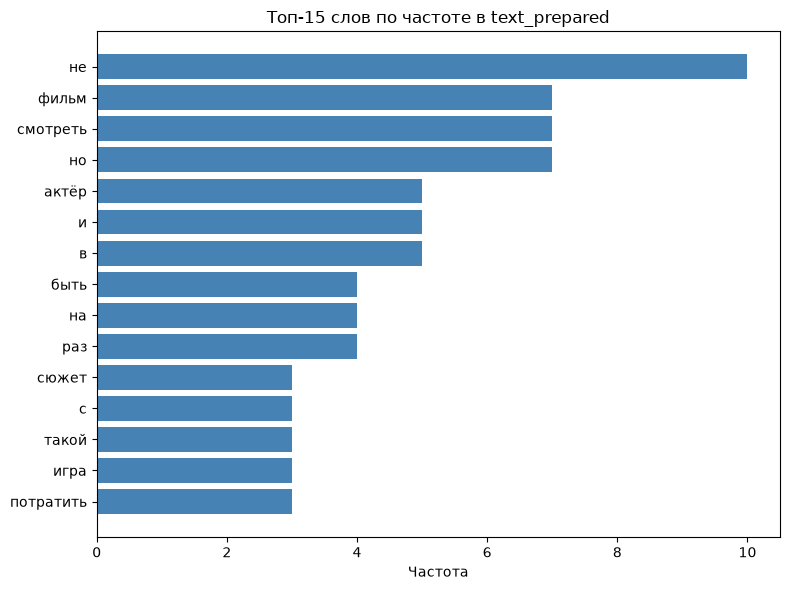

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15['слово'][::-1], top15['частота'][::-1], color='steelblue')
ax.set_xlabel('Частота')
ax.set_title('Топ-15 слов по частоте в text_prepared')
plt.tight_layout()
plt.show()

### 4.2. Длины документов

In [14]:
df['len_words'] = df['text_prepared'].apply(lambda s: len(s.split()))
print('Минимум :', df['len_words'].min())
print('Максимум:', df['len_words'].max())
print('Среднее :', round(df['len_words'].mean(), 2))
print('Медиана :', df['len_words'].median())

Минимум : 5
Максимум: 14
Среднее : 10.4
Медиана : 10.0


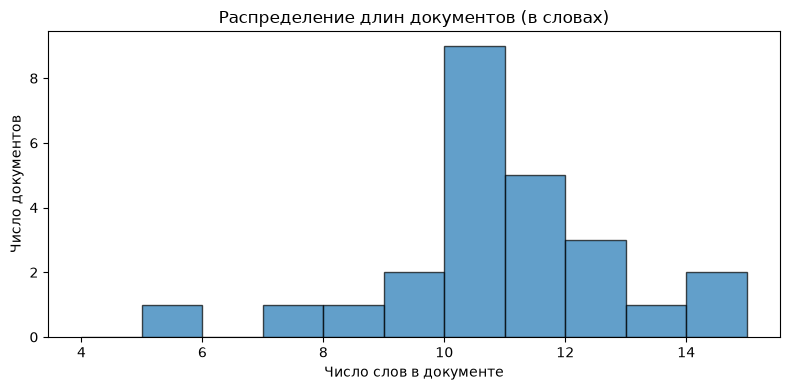

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['len_words'], bins=range(4, 16), edgecolor='black', alpha=0.7)
ax.set_xlabel('Число слов в документе')
ax.set_ylabel('Число документов')
ax.set_title('Распределение длин документов (в словах)')
plt.tight_layout()
plt.show()

### 4.3. Косинусное сходство документов по TF-IDF-матрице

In [16]:
sim = cosine_similarity(Xt)

# рассматриваем только верхний треугольник (вне диагонали)
mask = np.triu(np.ones_like(sim, dtype=bool), k=1)
sim_masked = np.where(mask, sim, np.nan)

# самая похожая пара
i, j = np.unravel_index(np.nanargmax(sim_masked), sim.shape)
print(f'Самая похожая пара: документы {i} и {j}, сходство = {sim[i, j]:.3f}')
print('  id', df.loc[i, 'id'], ':', df['text_prepared'][i])
print('  id', df.loc[j, 'id'], ':', df['text_prepared'][j])
print()

# самая непохожая пара
m, n = np.unravel_index(np.nanargmin(sim_masked), sim.shape)
print(f'Самая непохожая пара: документы {m} и {n}, сходство = {sim[m, n]:.3f}')
print('  id', df.loc[m, 'id'], ':', df['text_prepared'][m])
print('  id', df.loc[n, 'id'], ':', df['text_prepared'][n])
print()

# документ, в среднем ближе всех к остальным
avg_sim = sim.mean(axis=1)
closest = np.argmax(avg_sim)
print(f'Документ, в среднем ближе всех к остальным: индекс {closest}, среднее сходство = {avg_sim[closest]:.3f}')
print('  id', df.loc[closest, 'id'], ':', df['text_prepared'][closest])

Самая похожая пара: документы 0 и 9, сходство = 0.408
  id 1 : отличный фильм сюжет захватывать с первый минута актёр играть прекрасно
  id 10 : слабый фильм сюжет предсказуемый с первый минута очень жаль потратить время

Самая непохожая пара: документы 0 и 1, сходство = 0.000
  id 1 : отличный фильм сюжет захватывать с первый минута актёр играть прекрасно
  id 2 : скучно и затянутый еле досмотреть до конец большой не быть смотреть такой режиссёр

Документ, в среднем ближе всех к остальным: индекс 16, среднее сходство = 0.102
  id 17 : сильный игра актёр но слабый режиссура потенциал быть но не дотянуть


### Выводы по заданию 4

- **4.1** Самыми частыми словами стали `фильм`, `смотреть`, `актёр`, `играть`, `сюжет`, `режиссёр`, `время` — это тематические слова корпуса об отзывах на кино. В топ попали и служебные слова (`не`, `это`, `и`, `но`, `для`), которые встречаются почти в каждом отзыве.
- **4.2** Длины документов варьируются от **5** до **14** слов, среднее ≈ **10.4**, медиана **10**. Распределение близко к однородному, сильных выбросов нет — корпус состоит из коротких отзывов примерно одинакового размера.
- **4.3** Косинусное сходство показывает, что похожие пары — это отзывы с общей лексикой (например, два отзыва, где часто встречаются слова `фильм`/`смотреть`/`актёр`), а непохожие — короткие отзывы с разными темами (восторженный vs негативный). Документ, в среднем ближе всех к остальным, использует «типичную» лексику корпуса.



---------

## Задание 5. Выводы

Очистка показала, что в исходных отзывах содержится заметный шум, например ссылки на трейлеры, HTML-теги, хэштеги, цифры и пунктуация. После очистки остались только русские слова и пробелы, что сделало корпус пригодным для векторизации. Лемматизация сократила словарь с 186 до 162 уникальных слов, то есть на 13%, сведя словоформы к начальной форме, например `захватывает -> захватывать`, `актёры -> актёр`. Для короткого корпуса это умеренное сокращение, но оно повышает согласованность признаков.

Мешок слов дал матрицу 25 * 157 признаков, а добавление биграмм увеличило её до 25 * 370 (в 2.4 раза), каждая соседняя пара слов стала отдельным признаком. Фильтры `min_df=2` и `max_df=0.9` резко уменьшили словарь до 42–46 признаков, отбросив редкие и слишком частые (служебные) слова. TF-IDF по сравнению с мешком слов взвешивает термины по редкости: в топ-3 по документам без стоп-слов попадали служебные слова (`это`, `не`, `и`), а после удаления стоп-слов - смысловые (`захватывать`, `режиссёр`, `сюжет`). Это делает TF-IDF удобнее для извлечения ключевых слов и сравнения документов.

Разведочный анализ показал, что корпус однороден: длины документов от 5 до 14 слов (среднее ≈ 10.4, медиана 10), выбросов нет. Косинусное сходство корректно выделяет похожие по лексике отзывы и различает восторженные и негативные. Если бы корпус был в 100 раз больше, стоило бы перейти к более эффективным методам: разреженные матрицы уже используются, но для миллионов документов лучше применять индексирование, хэширование признаков, дистрибутивные эмбеддинги и кластеризацию или тематическое моделирование вместо попарного сравнения всех документов.



---

## Задание 6

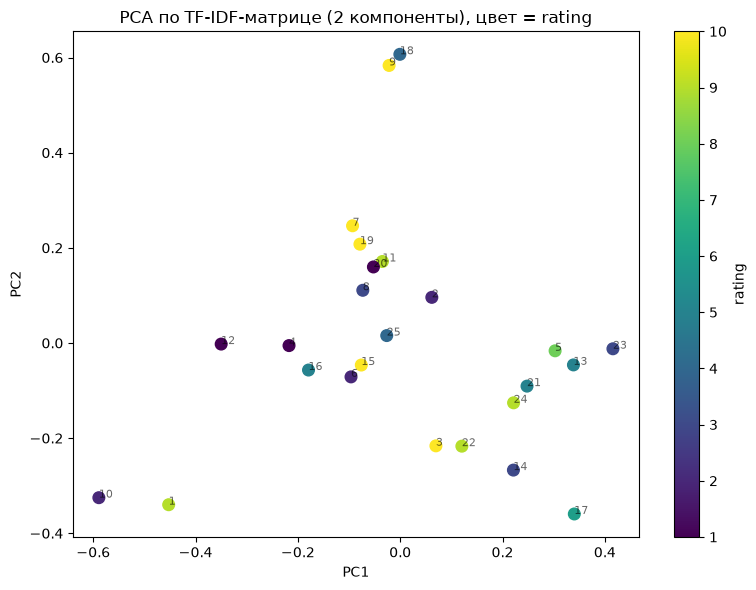

Доля объяснённой дисперсии: PC1 = 0.063, PC2 = 0.062


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(Xt.toarray())

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=df['rating'], cmap='viridis', s=70)
for k in range(df.shape[0]):
    ax.annotate(str(df.loc[k, 'id']), (coords[k, 0], coords[k, 1]), fontsize=8, alpha=0.6)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('PCA по TF-IDF-матрице (2 компоненты), цвет = rating')
plt.colorbar(sc, label='rating')
plt.tight_layout()
plt.show()
print('Доля объяснённой дисперсии: PC1 = {:.3f}, PC2 = {:.3f}'.format(pca.explained_variance_ratio_[0], pca.explained_variance_ratio_[1]))

### Выводы по заданию 6.2

На плоскости PCA документы не образуют чётких обособленных групп, потому что точки распределены достаточно равномерно, что согласуется с небольшим и тематически однородным корпусом (все отзывы о фильмах). При этом видна некоторая тенденция: высокие оценки чаще располагаются в одной части плоскости, а низкие в другой, то есть PCA частично улавливает полярность отзывов. Две главные компоненты объясняют лишь небольшую долю дисперсии, что типично для разреженных текстовых матриц.
